# 07 — How layers stack: residuals, LayerNorm and backpropagation

**Chapter 2** · suggested time: 40 min · CPU only (≈ 1 min of compute) · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_2/07_stacking_layers_and_backprop.ipynb)

![Roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/00_roadmap.png)

We have built the pieces separately: embeddings, attention, FeedForward. A GPT **stacks** them. This notebook answers two questions:

1. **Forward**: how does the output of one layer become the input of the next, and what happens to the tensor shapes?
2. **Backward**: when we call `loss.backward()`, how does the error signal travel through all the layers, and why do **the weights of one layer influence how the others learn**?

We will see that two ingredients, **residual connections** and **LayerNorm**, are what make a deep network trainable.

In [1]:
# On Google Colab: fetch the course repo (corpora + shared modules such as minigpt.py).
# Locally, this cell does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("minigpt.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_2

In [2]:
# Setup: imports and the chapter's shared module
import math
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import minigpt  # the minigpt.py file, next to this notebook
torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

text, tok, train_data, val_data = minigpt.prepare_data("shakespeare")
V = tok.vocab_size

PyTorch 2.15.0+cu132 | device: cpu


## 1. The chain rule on a two-layer network

Let's take the smallest possible network, with **numbers** (not tensors):

$$x \xrightarrow{\ \times w_1\ } a \xrightarrow{\ \text{ReLU}\ } h \xrightarrow{\ \times w_2\ } y \longrightarrow \mathcal{L} = (y - t)^2$$

With $x = 2$, $t = 1$, $w_1 = 0.5$, $w_2 = -1.5$: $a = 1$, $h = 1$, $y = -1.5$, $\mathcal{L} = 6.25$.

**Backward, starting from the end** (chain rule: we multiply the local derivatives):

| Quantity | Computation | Value |
|---|---|---|
| $\partial\mathcal{L}/\partial y$ | $2(y - t)$ | $-5$ |
| $\partial\mathcal{L}/\partial w_2$ | $\partial\mathcal{L}/\partial y \times h$ | $-5 \times 1 = -5$ |
| $\partial\mathcal{L}/\partial h$ | $\partial\mathcal{L}/\partial y \times w_2$ | $-5 \times (-1.5) = 7.5$ |
| $\partial\mathcal{L}/\partial a$ | $\partial\mathcal{L}/\partial h \times \text{ReLU}'(a)$ | $7.5 \times 1 = 7.5$ |
| $\partial\mathcal{L}/\partial w_1$ | $\partial\mathcal{L}/\partial a \times x$ | $7.5 \times 2 = 15$ |

**Read the last row:** $\dfrac{\partial\mathcal{L}}{\partial w_1} = 2(y-t)\cdot w_2 \cdot \text{ReLU}'(a)\cdot x$.

- The gradient of the **first** layer contains $w_2$, the weight of the **second** layer. **What layer 1 learns depends on the weights of layer 2.**
- The gradient of the **second** layer contains $h$, the output of the **first**. **What layer 2 learns depends on what layer 1 produces.**

Let's check with autograd, then look at two extreme cases.

In [3]:
def tiny_net(w1_val, w2_val, x=2.0, t=1.0):
    w1 = torch.tensor(w1_val, requires_grad=True)
    w2 = torch.tensor(w2_val, requires_grad=True)
    a = w1 * x
    h = torch.relu(a)
    y = w2 * h
    loss = (y - t) ** 2
    loss.backward()
    return loss.item(), w1.grad.item(), w2.grad.item()

for title, w1v, w2v in [("case from the table", 0.5, -1.5),
                        ("w2 = 0: layer 2 \"cuts\" the signal", 0.5, 0.0),
                        ("w1 < 0: ReLU off (dead neuron)", -0.5, -1.5)]:
    L, g1, g2 = tiny_net(w1v, w2v)
    print(f"{title:42s} loss={L:5.2f}  dL/dw1={g1:6.2f}  dL/dw2={g2:6.2f}")

case from the table                        loss= 6.25  dL/dw1= 15.00  dL/dw2= -5.00
w2 = 0: layer 2 "cuts" the signal          loss= 1.00  dL/dw1= -0.00  dL/dw2= -2.00
w1 < 0: ReLU off (dead neuron)             loss= 1.00  dL/dw1=  0.00  dL/dw2= -0.00


- **`w2 = 0`**: layer 1 receives **no** gradient, even though it is not to blame. A higher layer can **block** the learning of the lower layers.
- **ReLU off**: no gradient at all for **anyone** upstream, and layer 2 cannot learn anything either (its input $h$ is 0).

In a network of `L` layers, the gradient of a low layer is a **product of `L` factors**. If these factors are often < 1, the product **vanishes** (*vanishing gradient*); if they are often > 1, it **explodes**. This is the central problem of deep networks (Glorot & Bengio, 2010).

---
## 2. The Transformer block: LayerNorm + residuals

### LayerNorm: normalizing each position

`nn.LayerNorm(C)` takes **each position vector separately**, centers it (mean 0) and scales it (standard deviation 1) **over its `C` channels**, then applies a learned scale and shift (`γ`, `β`):

$$\text{LN}(x) = \gamma \odot \frac{x - \mu(x)}{\sigma(x) + \varepsilon} + \beta$$

Goal: keep activations at a reasonable scale from one layer to the next, whatever the depth (Ba et al., 2016). It mixes **neither positions nor examples**.

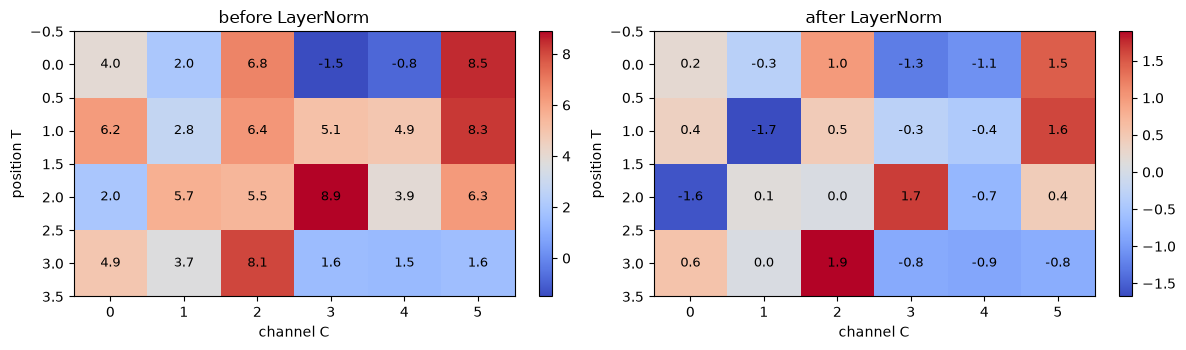

mean of each position after: [0.0, 0.0, -0.0, 0.0]
std of each position after:  [1.0, 1.0, 1.0, 1.0]


In [4]:
gen = torch.Generator().manual_seed(2027)
x_norm = torch.randn(1, 4, 6, generator=gen) * 3 + 5
y_norm = nn.LayerNorm(6, elementwise_affine=False)(x_norm)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, M, title in [(axes[0], x_norm[0], "before LayerNorm"), (axes[1], y_norm[0], "after LayerNorm")]:
    im = ax.imshow(M, cmap="coolwarm", aspect="auto"); ax.set_title(title)
    ax.set_xlabel("channel C"); ax.set_ylabel("position T")
    for i in range(4):
        for j in range(6):
            ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=9)
    plt.colorbar(im, ax=ax, fraction=.05)
plt.tight_layout(); plt.show()
print("mean of each position after:", [round(v, 3) for v in y_norm[0].mean(-1).tolist()])
print("std of each position after: ", [round(v, 3) for v in y_norm[0].std(-1, unbiased=False).tolist()])

### Residual connections: adding instead of replacing

Instead of `x = f(x)`, we write **`x = x + f(x)`**: each sub-layer **adds** its contribution to `x` instead of replacing it (He et al., 2016). Condition: `f(x)` must have **the same shape** as `x`. That is why multi-head attention ends with a projection back to `C` and the FeedForward comes back to `C`.

The full block (**pre-norm** version, like GPT-2):

In [5]:
class Block(nn.Module):
    """Transformer block (pre-norm): communication (attention) then computation (FeedForward)."""

    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.sa = minigpt.MultiHeadAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffwd = minigpt.FeedForward(n_embd, dropout)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))     # residual connection #1
        x = x + self.ffwd(self.ln2(x))   # residual connection #2
        return x


block = Block(n_embd=64, n_head=4, block_size=32, dropout=0.0)
x = torch.randn(2, 10, 64)
print("input:", tuple(x.shape), "-> output:", tuple(block(x).shape), "(same shape: we can stack)")

input: (2, 10, 64) -> output: (2, 10, 64) (same shape: we can stack)


## 3. Following a batch through the whole network (*forward*)

Let's take a 2-block GPT (the full code is detailed in notebook 08) and attach a **hook** to each layer: a small function called automatically after each `forward`, which prints the shape of the output. This shows **the exact order** in which the layers are chained.

In [6]:
torch.manual_seed(0)
small = minigpt.GPTLanguageModel(V, block_size=8, n_embd=16, n_head=2, n_layer=2, dropout=0.0)
xb, yb = minigpt.get_batch(train_data, batch_size=4, block_size=8)

trace = []
def hook(name):
    def f(module, inp, out):
        trace.append((name, tuple(out.shape)))
    return f

to_follow = ["token_embedding_table", "position_embedding_table"]
for i in range(2):
    to_follow += [f"blocks.{i}.ln1", f"blocks.{i}.sa.heads.0", f"blocks.{i}.sa.heads.1", f"blocks.{i}.sa",
                  f"blocks.{i}.ln2", f"blocks.{i}.ffwd.net.0", f"blocks.{i}.ffwd.net.1", f"blocks.{i}.ffwd", f"blocks.{i}"]
to_follow += ["ln_f", "lm_head"]
modules = dict(small.named_modules())
handles = [modules[n].register_forward_hook(hook(n)) for n in to_follow]
logits, loss = small(xb, yb)
for h in handles: h.remove()

print(f"input idx: {tuple(xb.shape)}")
for name, shape in trace:
    print(f"  {name:28s} -> {shape}")
print(f"loss (scalar): {loss.item():.3f}")

input idx: (4, 8)
  token_embedding_table        -> (4, 8, 16)
  position_embedding_table     -> (8, 16)
  blocks.0.ln1                 -> (4, 8, 16)
  blocks.0.sa.heads.0          -> (4, 8, 8)
  blocks.0.sa.heads.1          -> (4, 8, 8)
  blocks.0.sa                  -> (4, 8, 16)
  blocks.0.ln2                 -> (4, 8, 16)
  blocks.0.ffwd.net.0          -> (4, 8, 64)
  blocks.0.ffwd.net.1          -> (4, 8, 64)
  blocks.0.ffwd                -> (4, 8, 16)
  blocks.0                     -> (4, 8, 16)
  blocks.1.ln1                 -> (4, 8, 16)
  blocks.1.sa.heads.0          -> (4, 8, 8)
  blocks.1.sa.heads.1          -> (4, 8, 8)
  blocks.1.sa                  -> (4, 8, 16)
  blocks.1.ln2                 -> (4, 8, 16)
  blocks.1.ffwd.net.0          -> (4, 8, 64)
  blocks.1.ffwd.net.1          -> (4, 8, 64)
  blocks.1.ffwd                -> (4, 8, 16)
  blocks.1                     -> (4, 8, 16)
  ln_f                         -> (4, 8, 16)
  lm_head                      -> (4, 8, 65)

**What to read in the trace:**
- The two embeddings produce `(4, 8, 16)` and `(8, 16)`; their sum is the **entry point of the residual stream**.
- Each head produces `(4, 8, 8)` (= `C / n_head` channels); multi-head attention glues them back to `(4, 8, 16)`.
- The FeedForward goes through `(4, 8, 64)` (= `4C`) then comes back to `(4, 8, 16)`.
- **The whole core of the network keeps the shape `(B, T, C)`**: this is the "residual stream". Only `lm_head` converts it to `(B, T, V)`.

---
## 4. The residual stream, seen from the back (*backward*)

![Residual stream](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/07_residual_stream.png)

A good picture (Elhage et al., 2021): `x` is a **stream** (*residual stream*) that flows through the network from bottom to top. Each attention and each FeedForward **reads** the stream (via LayerNorm) and **writes** into the stream (by addition). After `L` blocks:

$$x_L = x_0 + f_1(\cdot) + f_2(\cdot) + \dots + f_{2L}(\cdot)$$

**Why this is crucial for the gradient:** the derivative of $x + f(x)$ with respect to $x$ is $1 + f'(x)$. The "$1$" means the gradient of the loss reaches the first layers and the embeddings **directly**, without being multiplied. Without residuals, it has to go through **all** the layers and becomes a product of `2L` factors (as in §1).

### Experiment: 8 blocks, with and without residuals / LayerNorm

We build four variants of an **8-block** GPT, identical except for these two ingredients. For each one, we measure **the norm of the gradient** received by each block after **a single** `backward()`, then we train for 200 steps.

In [7]:
class VariableBlock(nn.Module):
    def __init__(self, C, n_head, T, residuals, layernorm):
        super().__init__()
        self.residuals = residuals
        self.sa = minigpt.MultiHeadAttention(C, n_head, T, dropout=0.0)
        self.ffwd = minigpt.FeedForward(C, dropout=0.0)
        self.ln1 = nn.LayerNorm(C) if layernorm else nn.Identity()
        self.ln2 = nn.LayerNorm(C) if layernorm else nn.Identity()

    def forward(self, x):
        if self.residuals:
            x = x + self.sa(self.ln1(x))
            return x + self.ffwd(self.ln2(x))
        x = self.sa(self.ln1(x))          # no residual: we REPLACE x
        return self.ffwd(self.ln2(x))


class VariableGPT(nn.Module):
    def __init__(self, residuals, layernorm, C=64, n_head=4, n_layer=8, T=64):
        super().__init__()
        self.tok = nn.Embedding(V, C); self.pos = nn.Embedding(T, C)
        self.blocks = nn.Sequential(*[VariableBlock(C, n_head, T, residuals, layernorm) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(C); self.lm_head = nn.Linear(C, V)

    def forward(self, idx, targets):
        x = self.tok(idx) + self.pos(torch.arange(idx.shape[1]))
        logits = self.lm_head(self.ln_f(self.blocks(x)))
        return F.cross_entropy(logits.view(-1, V), targets.view(-1))


variants = {"residuals + LayerNorm": (True, True), "residuals only": (True, False),
            "LayerNorm only": (False, True), "neither": (False, False)}
norms, curves = {}, {}
for name, (r, ln) in variants.items():
    torch.manual_seed(0)
    m = VariableGPT(r, ln)
    xb, yb = minigpt.get_batch(train_data, 16, 64)
    m(xb, yb).backward()
    norms[name] = [math.sqrt(sum((p.grad ** 2).sum().item() for p in b.parameters())) for b in m.blocks]
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3)
    h = []
    for _ in range(200):
        xb, yb = minigpt.get_batch(train_data, 16, 64)
        loss = m(xb, yb); opt.zero_grad(); loss.backward(); opt.step(); h.append(loss.item())
    curves[name] = h
    print(f"{name:22s} gradient block 0: {norms[name][0]:.1e} | block 7: {norms[name][-1]:.1e} | loss after 200 steps: {sum(h[-20:]) / 20:.3f}")

residuals + LayerNorm  gradient block 0: 4.0e-01 | block 7: 4.4e-01 | loss after 200 steps: 2.477


residuals only         gradient block 0: 5.6e-01 | block 7: 7.6e-01 | loss after 200 steps: 2.475


LayerNorm only         gradient block 0: 1.2e+00 | block 7: 6.0e+00 | loss after 200 steps: 3.319


neither                gradient block 0: 1.9e-07 | block 7: 5.0e+00 | loss after 200 steps: 3.319


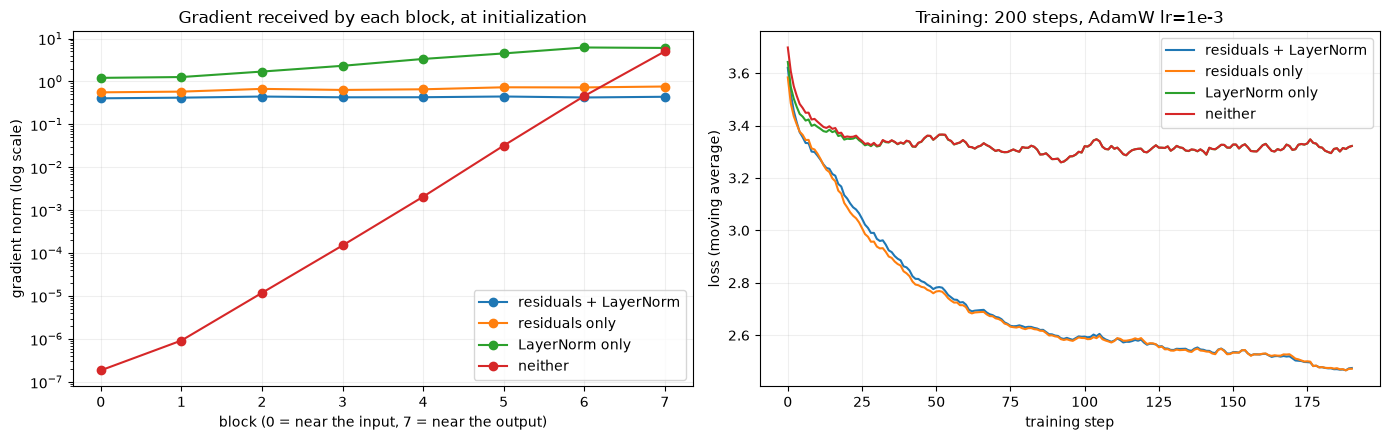

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, n in norms.items():
    axes[0].plot(range(8), n, marker="o", label=name)
axes[0].set_yscale("log"); axes[0].set_xlabel("block (0 = near the input, 7 = near the output)")
axes[0].set_ylabel("gradient norm (log scale)"); axes[0].set_title("Gradient received by each block, at initialization")
axes[0].legend(); axes[0].grid(alpha=.2)
for name, h in curves.items():
    smooth = torch.tensor(h).unfold(0, 10, 1).mean(1)
    axes[1].plot(smooth, label=name)
axes[1].set_xlabel("training step"); axes[1].set_ylabel("loss (moving average)")
axes[1].set_title("Training: 200 steps, AdamW lr=1e-3"); axes[1].legend(); axes[1].grid(alpha=.2)
plt.tight_layout(); plt.show()

**How to read it:**
- **Without residuals or LayerNorm**, the gradient of block 0 is **more than ten million times smaller** than that of block 7: the first blocks learn practically nothing. The network behaves as if it only had its last layers.
- **With residuals**, all blocks receive a gradient of **the same order of magnitude**: the "$+1$" highway works.
- LayerNorm alone prevents the collapse, but the gradient stays unbalanced (5 times stronger at the top than at the bottom) and the loss stays as high as with nothing: **residuals are what make the difference**. On this small network, "residuals only" does as well as "residuals + LayerNorm"; LayerNorm becomes essential for deeper networks and longer training runs, when the scale of the residual stream grows with each addition.

*(AdamW normalizes the step size, which partly hides the problem: with SGD, the gap would be even more dramatic.)*

---
## 5. One layer influences how the others learn

### Forward: changing one block changes everything above it

Let's slightly perturb the weights of **block 0** only, and measure how much the residual stream changes after each block.

In [9]:
torch.manual_seed(0)
gpt = minigpt.GPTLanguageModel(V, block_size=64, n_embd=64, n_head=4, n_layer=4, dropout=0.0)
xb, yb = minigpt.get_batch(train_data, 16, 64)

def stream(model):
    outputs = []
    handles = [b.register_forward_hook(lambda m, i, o: outputs.append(o.detach())) for b in model.blocks]
    logits, _ = model(xb)
    for h in handles: h.remove()
    return outputs, logits.detach()

before, logits_before = stream(gpt)
import copy
gpt_modified = copy.deepcopy(gpt)
with torch.no_grad():
    for p in gpt_modified.blocks[0].parameters():
        p.add_(0.05 * torch.randn_like(p))          # small perturbation of block 0 only
after, logits_after = stream(gpt_modified)

for i, (a, b) in enumerate(zip(before, after)):
    print(f"after block {i}: relative change of the stream = {((a - b).norm() / a.norm()).item():.3f}")
print(f"logits       : relative change               = {((logits_before - logits_after).norm() / logits_before.norm()).item():.3f}")

after block 0: relative change of the stream = 0.315
after block 1: relative change of the stream = 0.314
after block 2: relative change of the stream = 0.315
after block 3: relative change of the stream = 0.314
logits       : relative change               = 0.296


Changing block 0 changes **the input of every following block**: what each block has to learn depends on what the blocks below send it.

### Backward: the gradient of a block depends on the weights of the blocks above

This generalizes §1 (where $\partial\mathcal{L}/\partial w_1$ contained $w_2$). Let's compute the gradient of **block 0**, then change **only block 3** and recompute the gradient of block 0.

In [10]:
def block0_gradient(model):
    model.zero_grad()
    _, loss = model(xb, yb)
    loss.backward()
    return torch.cat([p.grad.flatten() for p in model.blocks[0].parameters()])

g_before = block0_gradient(gpt)
gpt_block3 = copy.deepcopy(gpt)
with torch.no_grad():
    for p in gpt_block3.blocks[3].parameters():
        p.add_(0.05 * torch.randn_like(p))          # we touch ONLY block 3
g_after = block0_gradient(gpt_block3)

print(f"relative change of the block 0 gradient: {((g_before - g_after).norm() / g_before.norm()).item():.3f}")
print("cosine between the two gradients:", round(F.cosine_similarity(g_before, g_after, dim=0).item(), 3))

relative change of the block 0 gradient: 0.368
cosine between the two gradients: 0.935


The weights of block 0 have not changed, and yet **their gradient has changed**: the direction in which block 0 will evolve depends on the weights of block 3, because the error signal goes through it during `backward()`.

**That is why we train all the layers together**, with a single loss: at each step, each layer adjusts while taking into account the current state of all the others. The layers **co-evolve**:

1. **forward**: block 0 → block 1 → … → logits → loss (each layer depends on the ones below);
2. **backward**: loss → lm_head → block 3 → … → block 0 → embeddings (each gradient depends on the layers above);
3. **step**: AdamW updates **all** the weights at the same time;
4. at the next step, each layer sees slightly different neighbors, and so on.

### How much does each part move in one step?

In [11]:
gpt_step = copy.deepcopy(gpt)
opt = torch.optim.AdamW(gpt_step.parameters(), lr=1e-3)
before = {n: p.detach().clone() for n, p in gpt_step.named_parameters()}
_, loss = gpt_step(xb, yb)
opt.zero_grad(); loss.backward(); opt.step()

groups = {}
for n, p in gpt_step.named_parameters():
    g = n.split(".")[0] if not n.startswith("blocks") else ".".join(n.split(".")[:2])
    d, w = groups.get(g, (0.0, 0.0))
    groups[g] = (d + ((p.detach() - before[n]) ** 2).sum().item(), w + (before[n] ** 2).sum().item())
for g, (d, w) in groups.items():
    print(f"{g:26s} |Δw| / |w| = {math.sqrt(d / w):.1e}")

token_embedding_table      |Δw| / |w| = 9.2e-04
position_embedding_table   |Δw| / |w| = 9.9e-04
blocks.0                   |Δw| / |w| = 1.2e-02
blocks.1                   |Δw| / |w| = 1.2e-02
blocks.2                   |Δw| / |w| = 1.2e-02
blocks.3                   |Δw| / |w| = 1.2e-02
ln_f                       |Δw| / |w| = 1.4e-03
lm_head                    |Δw| / |w| = 1.4e-02


**No part is left out.** With AdamW, each weight moves by about `lr = 1e-3` in absolute value (notebook 02). In **relative** terms, that is ≈ 1% for the linear layers of the blocks and of `lm_head` (their initial weights are small, ≈ 0.1) and ≈ 0.1% for the embeddings and the final LayerNorm (initial weights ≈ 1).

## Summary

- **Forward:** each layer receives the output of the previous one; at the core of the GPT, the shape stays `(B, T, C)`: this is the **residual stream**.
- **Backward:** the chain rule. The gradient of a layer is a **product** of the derivatives of the layers above it: it depends on **their weights**. And the inputs of each layer depend on the layers below. **The layers learn together.**
- **Residuals** (`x = x + f(x)`): the "$+1$" in the derivative is a highway for the gradient → all layers learn, even in a deep network.
- **LayerNorm**: normalizes each position over its `C` channels; keeps activations at a stable scale. **Pre-norm**: `x + f(LN(x))`.
- Without these two ingredients, an 8-block network sees its gradient vanish (×1e-7 at block 0).

**Check your understanding**
1. In `x = x + self.sa(self.ln1(x))`, why must `self.sa` return exactly the shape of `x`?
2. If the weights of `lm_head` were all zero, what gradient would the blocks receive? (Think of the `w2 = 0` case in §1.)
3. Why do we say that LayerNorm "does not make positions communicate"?

**Next → 08:** we put everything together in `GPTLanguageModel`.

### References
- K. He et al., [*Deep Residual Learning for Image Recognition*](https://arxiv.org/abs/1512.03385), CVPR 2016 — residual connections.
- J. L. Ba, J. R. Kiros, G. Hinton, [*Layer Normalization*](https://arxiv.org/abs/1607.06450), 2016.
- R. Xiong et al., [*On Layer Normalization in the Transformer Architecture*](https://arxiv.org/abs/2002.04745), ICML 2020 — why pre-norm stabilizes training.
- X. Glorot & Y. Bengio, [*Understanding the difficulty of training deep feedforward neural networks*](https://proceedings.mlr.press/v9/glorot10a.html), AISTATS 2010 — vanishing gradients.
- N. Elhage et al., [*A Mathematical Framework for Transformer Circuits*](https://transformer-circuits.pub/2021/framework/index.html), 2021 — the *residual stream* picture.
- A. Karpathy, [*The spelled-out intro to neural networks and backpropagation: building micrograd*](https://www.youtube.com/watch?v=VMj-3S1tku0) — backpropagation built by hand.
- I. Goodfellow, Y. Bengio, A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), §6.5 (*Back-Propagation*).